Figure 4: Validation on DLPFC dataset

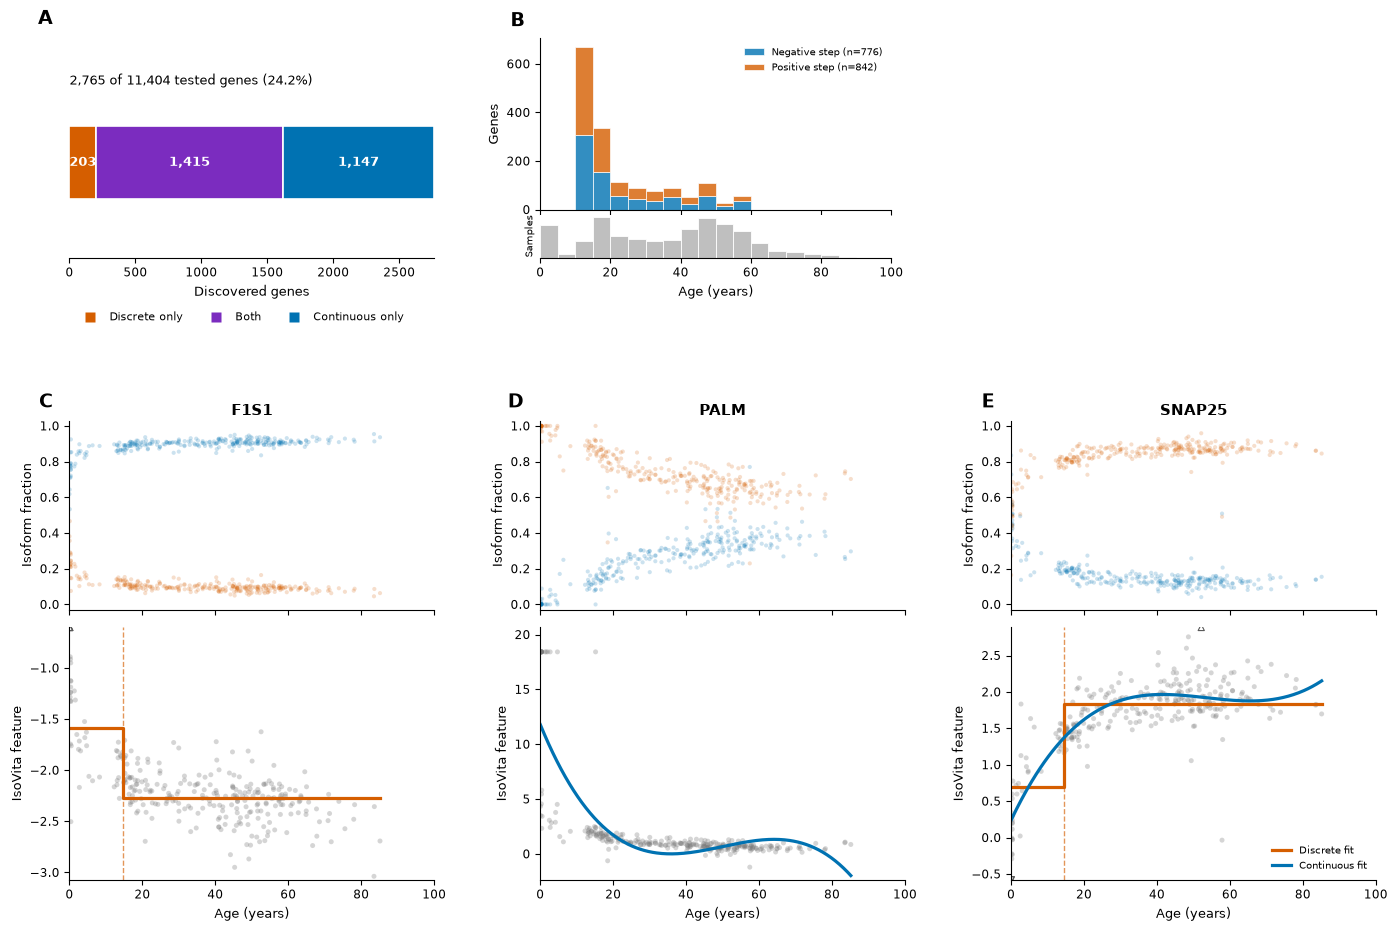

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from patsy import dmatrix, build_design_matrices


# ============================================================
# Paths
# ============================================================

DATA_DIR = Path(
    "/users/xchen5/IsoVita/data/DLPFC"
)

INPUT_DIR = (
    DATA_DIR
    / "isovita_inputs"
)

RESULT_DIR = (
    DATA_DIR
    / "isovita_results"
)


# ============================================================
# Representative genes
# ============================================================

# C — discrete
GENE_C = "CHS.51415"

# D — continuous
GENE_D = "CHS.25148"

# E — discrete + continuous
GENE_E = "CHS.32923"


GENE_LABELS = {
    GENE_C: "F1S1",
    GENE_D: "PALM",
    GENE_E: "SNAP25",
}


# ============================================================
# Plot colors
# ============================================================

COLOR_DISCRETE = "#D55E00"
COLOR_CONTINUOUS = "#0072B2"
COLOR_BOTH = "#7B2CBF"
COLOR_UNUSED = "#AAAAAA"
COLOR_POINTS = "#777777"


SIGNATURE_ORDER = [
    "Discrete only",
    "Both",
    "Continuous only",
]


SIGNATURE_COLORS = {
    "Discrete only": COLOR_DISCRETE,
    "Both": COLOR_BOTH,
    "Continuous only": COLOR_CONTINUOUS,
}


# ============================================================
# Load data
# ============================================================

metadata = pd.read_csv(
    INPUT_DIR / "metadata.tsv",
    sep="\t",
)


final_features = pd.read_csv(
    RESULT_DIR / "final_features.csv",
)


balance_summary = pd.read_csv(
    RESULT_DIR / "balance_summary.csv",
)


balance_loadings = pd.read_csv(
    RESULT_DIR / "balance_loadings.csv",
)


balance_features = pd.read_csv(
    RESULT_DIR / "balance_feature_matrix.csv",
    index_col=0,
)


metadata["sample_id"] = (
    metadata["sample_id"]
    .astype(str)
)


metadata["age"] = pd.to_numeric(
    metadata["age"],
    errors="coerce",
)


for df in [
    final_features,
    balance_summary,
    balance_loadings,
]:

    df["gene_id"] = (
        df["gene_id"]
        .astype(str)
    )


balance_loadings["transcript_id"] = (
    balance_loadings["transcript_id"]
    .astype(str)
)


balance_features.index = (
    balance_features.index
    .astype(str)
)


balance_features.columns = (
    balance_features.columns
    .astype(str)
)


sample_ids = (
    metadata["sample_id"]
    .tolist()
)


ages = (
    metadata["age"]
    .to_numpy(dtype=float)
)


balance_features = (
    balance_features
    .loc[:, sample_ids]
)


# ============================================================
# Helpers
# ============================================================

def as_bool(series):

    if pd.api.types.is_bool_dtype(series):
        return series.fillna(False)

    return (
        series
        .astype(str)
        .str.lower()
        .map({
            "true": True,
            "false": False,
            "1": True,
            "0": False,
        })
        .fillna(False)
        .astype(bool)
    )


final_features["discrete_fdr_significant"] = as_bool(
    final_features["discrete_fdr_significant"]
)


final_features["continuous_fdr_significant"] = as_bool(
    final_features["continuous_fdr_significant"]
)


def get_signature(row):

    discrete = (
        row["discrete_fdr_significant"]
    )

    continuous = (
        row["continuous_fdr_significant"]
    )

    if discrete and continuous:
        return "Both"

    if discrete:
        return "Discrete only"

    if continuous:
        return "Continuous only"

    return "Neither"


final_features["signature"] = (
    final_features.apply(
        get_signature,
        axis=1,
    )
)


def get_row(gene_id):

    hit = final_features.loc[
        final_features["gene_id"].eq(
            gene_id
        )
    ]

    if hit.empty:

        raise ValueError(
            f"{gene_id} not found in final_features.csv"
        )

    return hit.iloc[0].copy()


row_C = get_row(
    GENE_C
)

row_D = get_row(
    GENE_D
)

row_E = get_row(
    GENE_E
)


# ============================================================
# Load TPM only for representative genes
# ============================================================

chunks = []


for chunk in pd.read_csv(
    INPUT_DIR / "tpm.tsv",
    sep="\t",
    chunksize=20000,
):

    chunk["gene_id"] = (
        chunk["gene_id"]
        .astype(str)
    )

    keep = (
        chunk["gene_id"]
        .isin({
            GENE_C,
            GENE_D,
            GENE_E,
        })
    )

    if keep.any():

        chunks.append(
            chunk.loc[
                keep
            ].copy()
        )


if not chunks:

    raise ValueError(
        "None of the representative genes were found in tpm.tsv"
    )


example_tpm = pd.concat(
    chunks,
    ignore_index=True,
)


example_tpm["transcript_id"] = (
    example_tpm["transcript_id"]
    .astype(str)
)


# ============================================================
# Continuous fit
# ============================================================

def fit_spline(
    age,
    y,
    grid_size=300,
):

    age = np.asarray(
        age,
        dtype=float,
    )

    y = np.asarray(
        y,
        dtype=float,
    )

    keep = (
        np.isfinite(age)
        &
        np.isfinite(y)
    )

    age = age[keep]
    y = y[keep]

    X_df = dmatrix(
        (
            "bs(age, df=3, degree=3, "
            "include_intercept=False)"
        ),
        {
            "age": age
        },
        return_type="dataframe",
    )

    X = np.asarray(
        X_df,
        dtype=float,
    )

    beta = np.linalg.lstsq(
        X,
        y,
        rcond=None,
    )[0]

    age_grid = np.linspace(
        age.min(),
        age.max(),
        grid_size,
    )

    X_grid = np.asarray(
        build_design_matrices(
            [
                X_df.design_info
            ],
            {
                "age": age_grid
            },
        )[0],
        dtype=float,
    )

    return (
        age_grid,
        X_grid @ beta,
    )


# ============================================================
# Robust feature limits
# ============================================================

def robust_ylim(y):

    y = np.asarray(
        y,
        dtype=float,
    )

    y = y[
        np.isfinite(y)
    ]

    low, high = np.quantile(
        y,
        [
            0.01,
            0.99,
        ],
    )

    span = (
        high
        - low
    )

    if (
        not np.isfinite(span)
        or span <= 0
    ):

        span = max(
            np.ptp(y),
            1.0,
        )

    return (
        low - 0.12 * span,
        high + 0.12 * span,
    )


# ============================================================
# Feature scatter
# ============================================================

def plot_balance_points(
    ax,
    age,
    y,
    ymin,
    ymax,
):

    age = np.asarray(
        age,
        dtype=float,
    )

    y = np.asarray(
        y,
        dtype=float,
    )

    keep = (
        np.isfinite(age)
        &
        np.isfinite(y)
    )

    age = age[keep]
    y = y[keep]

    inside = (
        (y >= ymin)
        &
        (y <= ymax)
    )

    below = (
        y < ymin
    )

    above = (
        y > ymax
    )

    ax.scatter(
        age[inside],
        y[inside],
        s=13,
        alpha=0.30,
        color=COLOR_POINTS,
        edgecolors="none",
        rasterized=True,
    )

    if below.any():

        ax.scatter(
            age[below],
            np.full(
                below.sum(),
                ymin,
            ),
            marker="v",
            s=20,
            facecolors="none",
            edgecolors="0.35",
            linewidths=0.8,
        )

    if above.any():

        ax.scatter(
            age[above],
            np.full(
                above.sum(),
                ymax,
            ),
            marker="^",
            s=20,
            facecolors="none",
            edgecolors="0.35",
            linewidths=0.8,
        )


# ============================================================
# Isoform fractions
# ============================================================

def get_isoform_fractions(
    gene_id
):

    load = (
        balance_loadings.loc[
            balance_loadings[
                "gene_id"
            ].eq(gene_id),
            [
                "transcript_id",
                "balance_assignment",
            ],
        ]
        .copy()
    )

    isoforms = (
        load["transcript_id"]
        .tolist()
    )

    gene = (
        example_tpm.loc[
            (
                example_tpm[
                    "gene_id"
                ].eq(gene_id)
            )
            &
            (
                example_tpm[
                    "transcript_id"
                ].isin(isoforms)
            )
        ]
        .set_index(
            "transcript_id"
        )
        .loc[
            isoforms,
            sample_ids,
        ]
        .apply(
            pd.to_numeric,
            errors="coerce",
        )
        .T
    )

    totals = (
        gene.sum(axis=1)
    )

    gene = gene.loc[
        np.isfinite(totals)
        &
        totals.gt(0)
    ]

    fractions = gene.div(
        gene.sum(axis=1),
        axis=0,
    )

    fractions["age"] = (
        metadata
        .set_index("sample_id")
        .loc[
            fractions.index,
            "age",
        ]
        .to_numpy(dtype=float)
    )

    assignments = (
        load
        .set_index(
            "transcript_id"
        )[
            "balance_assignment"
        ]
        .astype(int)
        .to_dict()
    )

    return (
        fractions,
        assignments,
    )


def plot_isoform_fractions(
    ax,
    gene_id,
):

    fractions, assignments = (
        get_isoform_fractions(
            gene_id
        )
    )

    isoforms = [
        col
        for col
        in fractions.columns
        if col != "age"
    ]

    for tx in isoforms:

        assignment = (
            assignments[tx]
        )

        if assignment == 1:

            color = (
                COLOR_DISCRETE
            )

        elif assignment == -1:

            color = (
                COLOR_CONTINUOUS
            )

        else:

            color = (
                COLOR_UNUSED
            )

        x = (
            fractions["age"]
            .to_numpy(dtype=float)
        )

        y = (
            fractions[tx]
            .to_numpy(dtype=float)
        )

        keep = (
            np.isfinite(x)
            &
            np.isfinite(y)
        )

        ax.scatter(
            x[keep],
            y[keep],
            s=9,
            alpha=0.20,
            color=color,
            edgecolors="none",
            rasterized=True,
        )

    ax.set_xlim(
        0,
        100,
    )

    ax.set_ylim(
        -0.03,
        1.03,
    )

    ax.set_ylabel(
        "Isoform fraction"
    )

    ax.tick_params(
        axis="x",
        labelbottom=False,
    )

    ax.spines[
        "top"
    ].set_visible(False)

    ax.spines[
        "right"
    ].set_visible(False)


# ============================================================
# IsoVita feature
# ============================================================

def plot_feature(
    ax,
    row,
    *,
    discrete=False,
    continuous=False,
):

    gene_id = (
        row["gene_id"]
    )

    y = (
        balance_features.loc[
            gene_id,
            sample_ids,
        ]
        .to_numpy(dtype=float)
    )

    keep = (
        np.isfinite(ages)
        &
        np.isfinite(y)
    )

    age = ages[keep]
    y = y[keep]

    ymin, ymax = (
        robust_ylim(y)
    )

    plot_balance_points(
        ax,
        age,
        y,
        ymin,
        ymax,
    )

    if discrete:

        change = float(
            row[
                "discrete_change_age"
            ]
        )

        left = float(
            row[
                "discrete_left_mean"
            ]
        )

        right = float(
            row[
                "discrete_right_mean"
            ]
        )

        ax.plot(
            [
                age.min(),
                change,
                change,
                age.max(),
            ],
            [
                left,
                left,
                right,
                right,
            ],
            color=COLOR_DISCRETE,
            linewidth=2.3,
            label="Discrete fit",
        )

        ax.axvline(
            change,
            color=COLOR_DISCRETE,
            linestyle="--",
            linewidth=1.0,
            alpha=0.65,
        )

    if continuous:

        age_grid, fit_grid = (
            fit_spline(
                age,
                y,
            )
        )

        ax.plot(
            age_grid,
            fit_grid,
            color=COLOR_CONTINUOUS,
            linewidth=2.3,
            label="Continuous fit",
        )

    ax.set_xlim(
        0,
        100,
    )

    ax.set_ylim(
        ymin,
        ymax,
    )

    ax.set_xlabel(
        "Age (years)"
    )

    ax.set_ylabel(
        "IsoVita feature"
    )

    ax.spines[
        "top"
    ].set_visible(False)

    ax.spines[
        "right"
    ].set_visible(False)

    if (
        discrete
        and continuous
    ):

        ax.legend(
            frameon=False,
            fontsize=7.0,
            loc="lower right",
        )


# ============================================================
# Summary statistics
# ============================================================

counts = (
    final_features[
        "signature"
    ]
    .value_counts()
    .reindex(
        SIGNATURE_ORDER,
        fill_value=0,
    )
)


n_tested = int(
    balance_summary[
        "status"
    ]
    .eq("ok")
    .sum()
)


n_selected = len(
    final_features
)


discrete_hits = (
    final_features.loc[
        final_features[
            "discrete_fdr_significant"
        ]
    ]
    .copy()
)


discrete_hits[
    "step_direction"
] = np.where(
    discrete_hits[
        "discrete_step_effect"
    ] >= 0,
    "Positive step",
    "Negative step",
)


# ============================================================
# Figure
# ============================================================

plt.rcParams.update({
    "font.size": 9.5,
    "axes.titlesize": 10.5,
    "axes.labelsize": 9.5,
    "xtick.labelsize": 8.3,
    "ytick.labelsize": 8.3,
})


fig = plt.figure(
    figsize=(
        14.2,
        9.4,
    )
)


outer = fig.add_gridspec(
    2,
    6,
    height_ratios=[
        0.74,
        1.55,
    ],
    hspace=0.48,
    wspace=0.82,
)


# ============================================================
# Panel A — discovery summary
# ============================================================

ax_A = fig.add_subplot(
    outer[
        0,
        0:2,
    ]
)


left = 0


for label in SIGNATURE_ORDER:

    count = int(
        counts[label]
    )

    ax_A.barh(
        0,
        count,
        left=left,
        height=0.38,
        color=(
            SIGNATURE_COLORS[
                label
            ]
        ),
        edgecolor="white",
        linewidth=1.2,
    )

    ax_A.text(
        left + count / 2,
        0,
        f"{count:,}",
        ha="center",
        va="center",
        color="white",
        fontweight="bold",
    )

    left += count


ax_A.set_xlim(
    0,
    n_selected,
)


ax_A.set_ylim(
    -0.5,
    0.65,
)


ax_A.set_yticks([])


ax_A.set_xlabel(
    "Discovered genes"
)


ax_A.text(
    0,
    0.79,
    (
        f"{n_selected:,} of "
        f"{n_tested:,} tested genes "
        f"({100 * n_selected / n_tested:.1f}%)"
    ),
    transform=ax_A.transAxes,
)


legend_A = [

    Line2D(
        [0],
        [0],
        marker="s",
        linestyle="",
        markersize=7,
        markerfacecolor=(
            SIGNATURE_COLORS[
                label
            ]
        ),
        markeredgecolor="none",
        label=label,
    )

    for label
    in SIGNATURE_ORDER
]


ax_A.legend(
    handles=legend_A,
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(
        0,
        -0.20,
    ),
    ncol=3,
    fontsize=7.8,
)


for spine in [
    "top",
    "right",
    "left",
]:

    ax_A.spines[
        spine
    ].set_visible(False)


# ============================================================
# Panel B — discrete changepoints
# ============================================================

gs_BC = (
    outer[
        0,
        2:6,
    ]
    .subgridspec(
        1,
        2,
        wspace=0.38,
    )
)


gs_B = (
    gs_BC[
        0,
        0,
    ]
    .subgridspec(
        2,
        1,
        height_ratios=[
            1.0,
            0.25,
        ],
        hspace=0.05,
    )
)


ax_B = fig.add_subplot(
    gs_B[
        0,
        0,
    ]
)


ax_B_age = fig.add_subplot(
    gs_B[
        1,
        0,
    ],
    sharex=ax_B,
)


bins_age = np.arange(
    0,
    101,
    5,
)


negative_steps = (
    discrete_hits.loc[
        discrete_hits[
            "step_direction"
        ].eq(
            "Negative step"
        ),
        "discrete_change_age",
    ]
    .dropna()
    .to_numpy()
)


positive_steps = (
    discrete_hits.loc[
        discrete_hits[
            "step_direction"
        ].eq(
            "Positive step"
        ),
        "discrete_change_age",
    ]
    .dropna()
    .to_numpy()
)


ax_B.hist(
    [
        negative_steps,
        positive_steps,
    ],
    bins=bins_age,
    stacked=True,
    color=[
        COLOR_CONTINUOUS,
        COLOR_DISCRETE,
    ],
    alpha=0.80,
    edgecolor="white",
    linewidth=0.6,
    label=[
        (
            "Negative step "
            f"(n={len(negative_steps):,})"
        ),
        (
            "Positive step "
            f"(n={len(positive_steps):,})"
        ),
    ],
)


ax_B.set_xlim(
    0,
    100,
)


ax_B.set_ylabel(
    "Genes"
)


ax_B.legend(
    frameon=False,
    fontsize=7.0,
    loc="upper right",
)


ax_B.tick_params(
    axis="x",
    labelbottom=False,
)


ax_B.spines[
    "top"
].set_visible(False)


ax_B.spines[
    "right"
].set_visible(False)


ax_B_age.hist(
    ages[
        np.isfinite(
            ages
        )
    ],
    bins=bins_age,
    color="0.75",
    edgecolor="white",
    linewidth=0.6,
)


ax_B_age.set_xlabel(
    "Age (years)"
)


ax_B_age.set_yticks([])


ax_B_age.set_ylabel(
    "Samples",
    fontsize=7.0,
)


ax_B_age.spines[
    "top"
].set_visible(False)


ax_B_age.spines[
    "right"
].set_visible(False)


ax_B_age.spines[
    "left"
].set_visible(False)



ax_blank = fig.add_subplot(
    gs_BC[
        0,
        1,
    ]
)

ax_blank.axis(
    "off"
)


# ============================================================
# Representative gene panels
# ============================================================

def example_axes(spec):

    gs = spec.subgridspec(
        2,
        1,
        height_ratios=[
            0.75,
            1.0,
        ],
        hspace=0.08,
    )

    return (
        fig.add_subplot(
            gs[
                0,
                0,
            ]
        ),
        fig.add_subplot(
            gs[
                1,
                0,
            ]
        ),
    )


ax_C_frac, ax_C = example_axes(
    outer[
        1,
        0:2,
    ]
)


ax_D_frac, ax_D = example_axes(
    outer[
        1,
        2:4,
    ]
)


ax_E_frac, ax_E = example_axes(
    outer[
        1,
        4:6,
    ]
)


# ============================================================
# Panel C — F1S1, discrete
# ============================================================

ax_C_frac.set_title(
    GENE_LABELS[
        GENE_C
    ],
    fontweight="bold",
    pad=4,
)


plot_isoform_fractions(
    ax_C_frac,
    GENE_C,
)


plot_feature(
    ax_C,
    row_C,
    discrete=True,
)


# ============================================================
# Panel D — PALM, continuous
# ============================================================

ax_D_frac.set_title(
    GENE_LABELS[
        GENE_D
    ],
    fontweight="bold",
    pad=4,
)


plot_isoform_fractions(
    ax_D_frac,
    GENE_D,
)


plot_feature(
    ax_D,
    row_D,
    continuous=True,
)


# ============================================================
# Panel E — SNAP25, both
# ============================================================

ax_E_frac.set_title(
    GENE_LABELS[
        GENE_E
    ],
    fontweight="bold",
    pad=4,
)


plot_isoform_fractions(
    ax_E_frac,
    GENE_E,
)


plot_feature(
    ax_E,
    row_E,
    discrete=True,
    continuous=True,
)


# ============================================================
# Panel labels
# ============================================================

panel_labels = {
    ax_A: "A",
    ax_B: "B",
    ax_C_frac: "C",
    ax_D_frac: "D",
    ax_E_frac: "E",
}


for ax, label in (
    panel_labels.items()
):

    ax.text(
        -0.045,
        1.045,
        label,
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=14,
        fontweight="bold",
        clip_on=False,
    )


# ============================================================
# Final layout
# ============================================================

fig.subplots_adjust(
    left=0.065,
    right=0.985,
    top=0.965,
    bottom=0.07,
)


plt.show()